In [1]:
import os
import glob
import numpy as np
np.random.seed(12345)
import pandas as pd

import matplotlib.pyplot as plt
import matplotlib.image as mpimg

import re
import warnings
warnings.filterwarnings('ignore')

In [2]:
# Automatically detect if running on Kaggle or Locally
IS_KAGGLE = os.path.exists('/kaggle/input')
BASE_DIR = '/kaggle/input/competitions/rogii-wellbore-geology-prediction' if IS_KAGGLE else '../data'

print(f"Running on {'Kaggle' if IS_KAGGLE else 'Local Environment'}")
print(f"Data Directory: {BASE_DIR}")

Running on Local Environment
Data Directory: ../data


---

## 1-Training-Data
>Each well has three associated files.
Each well is identified by a unique 8-character hash (e.g., `015fe0d2`).

In [4]:
train_data = os.path.join(BASE_DIR, "train")
file_paths = sorted(os.listdir(train_data))
file_paths[:10]

['.DS_Store',
 '000d7d20.png',
 '000d7d20__horizontal_well.csv',
 '000d7d20__typewell.csv',
 '00bbac68.png',
 '00bbac68__horizontal_well.csv',
 '00bbac68__typewell.csv',
 '00e12e8b.png',
 '00e12e8b__horizontal_well.csv',
 '00e12e8b__typewell.csv']

In [5]:
# Regex pattern: 
pattern = re.compile(r'([^/\\]+)__horizontal_well\.csv')

well_names = []
for path in file_paths:
    match = pattern.search(path)
    if match:
        well_names.append(match.group(1))

print("Extracted Well Names:")
print(len(well_names), "Well Names")
print("Every Well Name has 3 files: ")
print(len(file_paths) / 3 == len(well_names))

Extracted Well Names:
773 Well Names
Every Well Name has 3 files: 
False


In [6]:
sample_well = np.random.choice(well_names)

horizontal_well_csv = pd.read_csv(train_data + f"/{sample_well}__horizontal_well.csv")
typewell_csv = pd.read_csv(train_data + f"/{sample_well}__typewell.csv")
pic = train_data + f"/{sample_well}.png"

sample_well, horizontal_well_csv.shape, typewell_csv.shape

(np.str_('a3518960'), (6992, 13), (5137, 3))

In [7]:
horizontal_well_csv.head()

,MD,X,Y,Z,ANCC,ASTNU,ASTNL,EGFDU,EGFDL,BUDA,TVT,GR,TVT_input
0,11427.0,3024034.15,1108541.62,-9216.25,-9918.02,-10077.58,-10151.22,-10281.01,-10325.54,-10448.65,11054.62,77.286692,11054.62
1,11428.0,3024034.20,1108541.63,-9217.25,-9918.19,-10077.75,-10151.39,-10281.18,-10325.71,-10448.82,11055.44,77.168139,11055.44
2,11429.0,3024034.25,1108541.64,-9218.25,-9918.36,-10077.92,-10151.56,-10281.36,-10325.88,-10448.99,11056.27,77.504039,11056.27
3,11430.0,3024034.30,1108541.65,-9219.25,-9918.54,-10078.09,-10151.73,-10281.53,-10326.05,-10449.17,11057.10,79.232937,11057.10
4,11431.0,3024034.35,1108541.67,-9220.25,-9918.71,-10078.27,-10151.90,-10281.70,-10326.22,-10449.34,11057.93,80.072688,11057.93


<Axes: >

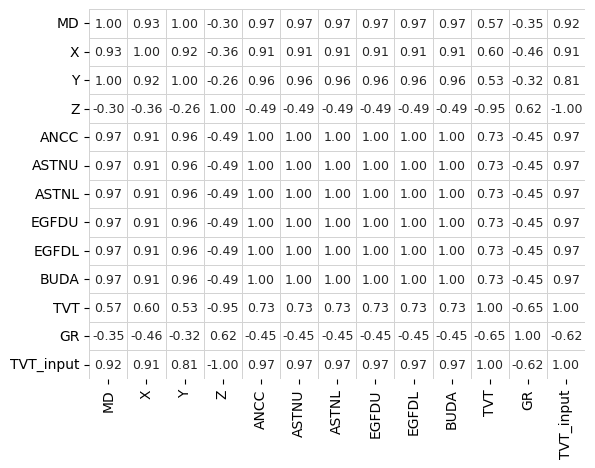

In [10]:
from matplotlib.colors import LinearSegmentedColormap
import seaborn as sns

flat = LinearSegmentedColormap.from_list("flat", ["white", "white"])

hw = horizontal_well_csv.copy()
sns.heatmap(
    hw.corr(),
    annot=True, fmt=".2f",
    cmap=flat,
    linewidths=0.5, linecolor="lightgray",   # grid lines so cells are still visible
    cbar=False,
    annot_kws={"size": 9},
)

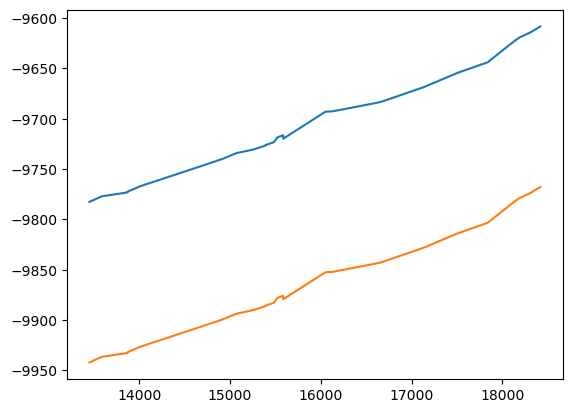

In [15]:
e = hw[hw['TVT_input'].isna()]
plt.plot(e['MD'], e['ANCC'])
plt.plot(e['MD'], e['ASTNU'])